# Notebook 04 — User Profile Agent

**Purpose**: Implement the **User Profile Agent** — a hierarchical memory system with temporal decay that builds and maintains dynamic user interest profiles from interaction history.

**Architecture** (from RecAgent [3]):
```
User Memory
├── SensoryMemory  — current session query + context
├── ShortTermMemory — last 30 interactions (vector store)
└── LongTermMemory — historical profile, topic evolution
```

**Outputs**:
- `UserProfileVector ∈ ℝ^1024` — dense profile embedding
- `DomainKeywords[]` — extracted interest keywords
- `RecentInterestShift` — boolean flag for topic drift detection

In [3]:
# ── Dependencies ────────────────────────────────────────────────────────────
import json
import math
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timedelta
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm

warnings.filterwarnings("ignore")

import os
def _find(name):
    for root in ["/kaggle/input", "/kaggle/working", "..", "."]:
        r = Path(root)
        if r.exists():
            hits = list(r.rglob(name))
            if hits:
                return hits[0]
    return None
IS_KAGGLE = os.path.exists("/kaggle")
OUT_DIR   = Path("/kaggle/working") if IS_KAGGLE else Path("../data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Temporal decay rate
DECAY_LAMBDA = 0.1   # α = exp(-λ * Δt_days)
TOPIC_SHIFT_THRESHOLD = 0.60  # cosine similarity below this → topic shift detected
SHORT_TERM_WINDOW = 30  # papers in short-term memory

In [4]:
# ── Load data ─────────────────────────────────────────────────────────────────
papers_df = pd.read_json(
    "/kaggle/input/datasets/reapers2025/paper-metadata/paper_metadata.json"
)

rated_df = pd.read_csv(
    "/kaggle/input/datasets/joytuntonny/recommendation-system/rated_papers.csv"
)

implicit_df = pd.read_csv(
    "/kaggle/input/datasets/joytuntonny/recommendation-system/implicit_interactions.csv"
)

# use e5 (from nb03) if present, else the existing embeddings
e5_emb_path = _find("paper_embeddings_e5.npy")
e5_map_path = _find("paper_id_mapping_e5.json")

if e5_emb_path and e5_map_path:
    emb_matrix = np.load(e5_emb_path)
    with open(e5_map_path, "r", encoding="utf-8") as f:
        id_mapping = json.load(f)
else:
    emb_matrix = np.load(
        "/kaggle/input/datasets/reapers2025/acl-embeddings/paper_embeddings_full.npy"
    )
    with open(
        "/kaggle/input/datasets/reapers2025/acl-embeddings/paper_id_mapping.json",
        "r",
        encoding="utf-8"
    ) as f:
        id_mapping = json.load(f)

print("embeddings:", emb_matrix.shape)

# column detection
id_col = next((c for c in ["arxiv_id", "paper_id", "paperId", "id"] if c in papers_df.columns), None)

user_col = next((c for c in ["user_id", "userId", "user"] if c in rated_df.columns), None)

paper_col = next((c for c in ["arxiv_id", "paper_id", "paperId", "id"] if c in rated_df.columns), None)

rating_col = next((c for c in ["rating", "score", "relevance"] if c in rated_df.columns), None)

print(
    f"Papers: {len(papers_df)}, Ratings: {len(rated_df)}, Implicit: {len(implicit_df)}"
)

embeddings: (239618, 1024)
Papers: 239618, Ratings: 774092, Implicit: 556324


## 1. User Memory Dataclass

In [5]:
@dataclass
class SensoryMemory:
    """Current session query and context window."""
    query: str = ""
    context_papers: List[str] = field(default_factory=list)  # paper IDs seen this session
    timestamp: datetime = field(default_factory=datetime.now)


@dataclass
class ShortTermMemory:
    """Last N papers read/saved — stored as ID list with timestamps."""
    interactions: List[Dict] = field(default_factory=list)  # {paper_id, rating, timestamp}
    max_size: int = SHORT_TERM_WINDOW

    def add(self, paper_id: str, rating: float, timestamp: Optional[datetime] = None):
        entry = {"paper_id": paper_id, "rating": rating,
                 "timestamp": (timestamp or datetime.now()).isoformat()}
        self.interactions.append(entry)
        if len(self.interactions) > self.max_size:
            self.interactions.pop(0)  # FIFO eviction

    def get_paper_ids(self) -> List[str]:
        return [i["paper_id"] for i in self.interactions]


@dataclass
class LongTermMemory:
    """Persistent research profile built from all interactions."""
    profile_vector: Optional[np.ndarray] = None   # (1024,) weighted mean embedding
    domain_keywords: List[str] = field(default_factory=list)
    interaction_count: int = 0
    last_updated: str = ""


@dataclass
class UserProfile:
    user_id: str
    sensory: SensoryMemory = field(default_factory=SensoryMemory)
    short_term: ShortTermMemory = field(default_factory=ShortTermMemory)
    long_term: LongTermMemory = field(default_factory=LongTermMemory)
    recent_interest_shift: bool = False


print("UserProfile dataclasses defined.")

UserProfile dataclasses defined.


## 2. Helper: Get Paper Embedding

In [6]:
def get_paper_embedding(paper_id: str) -> Optional[np.ndarray]:
    """Retrieve e5 embedding for a paper by ID."""
    idx = id_mapping.get(str(paper_id))
    if idx is not None and idx < len(emb_matrix):
        return emb_matrix[idx]
    return None


def temporal_weight(timestamp_str: str, lambda_: float = DECAY_LAMBDA) -> float:
    """Exponential decay weight: α = exp(-λ * days_since_interaction)."""
    try:
        ts = datetime.fromisoformat(timestamp_str)
        delta_days = max(0, (datetime.now() - ts).days)
        return math.exp(-lambda_ * delta_days)
    except Exception:
        return 1.0  # default weight if timestamp unavailable


print("Helper functions defined.")

Helper functions defined.


## 3. User Profile Agent — Core Class

In [7]:
class UserProfileAgent:
    """
    Agent 2: Dynamic user profile modeling with hierarchical memory
    and temporal interest decay.
    """

    def __init__(self, papers_df: pd.DataFrame, emb_matrix: np.ndarray, id_mapping: Dict):
        self.papers_df  = papers_df
        self.emb_matrix = emb_matrix
        self.id_mapping = id_mapping
        self._profiles: Dict[str, UserProfile] = {}

    # ── Profile initialization ──────────────────────────────────────────────
    def initialize_profile(self, user_id: str, interactions: List[Dict]) -> UserProfile:
        """
        Build a user profile from interaction history.
        interactions: list of {paper_id, rating, timestamp}
        """
        profile = UserProfile(user_id=user_id)

        # Sort by timestamp (oldest first)
        sorted_ints = sorted(interactions, key=lambda x: x.get("timestamp", ""))

        for inter in sorted_ints:
            profile.short_term.add(
                paper_id=str(inter["paper_id"]),
                rating=float(inter.get("rating", 1.0)),
                timestamp=datetime.fromisoformat(inter["timestamp"]) if "timestamp" in inter else None,
            )
            profile.long_term.interaction_count += 1

        # Build long-term profile vector (temporally weighted mean embedding)
        profile.long_term.profile_vector = self._compute_profile_vector(
            profile.short_term.interactions
        )
        profile.long_term.domain_keywords = self._extract_keywords(
            profile.short_term.get_paper_ids()
        )
        profile.long_term.last_updated = datetime.now().isoformat()

        self._profiles[user_id] = profile
        return profile

    # ── Profile vector computation ──────────────────────────────────────────
    def _compute_profile_vector(self, interactions: List[Dict]) -> Optional[np.ndarray]:
        """
        Temporally weighted mean of paper embeddings.
        UserProfile(t) = α·RecentInterests(t) + (1-α)·HistoricalProfile
        """
        embs, weights = [], []
        for inter in interactions:
            emb = get_paper_embedding(inter["paper_id"])
            if emb is not None:
                w = temporal_weight(inter.get("timestamp", datetime.now().isoformat()))
                w *= max(0.1, float(inter.get("rating", 1.0)))  # upweight highly rated
                embs.append(emb)
                weights.append(w)

        if not embs:
            return None

        weights = np.array(weights)
        weights /= weights.sum()  # normalize
        profile_vec = np.average(embs, axis=0, weights=weights)
        # L2 normalize
        norm = np.linalg.norm(profile_vec)
        return profile_vec / norm if norm > 0 else profile_vec

    # ── Keyword extraction ──────────────────────────────────────────────────
    def _extract_keywords(self, paper_ids: List[str], top_k: int = 20) -> List[str]:
        """Extract domain keywords from paper titles in the interaction history."""
        from collections import Counter
        import re

        id_col = next((c for c in ["arxiv_id", "paper_id", "paperId", "id"] if c in self.papers_df.columns), None)
        if id_col is None or "title" not in self.papers_df.columns:
            return []

        stop_words = {"a", "an", "the", "of", "in", "on", "for", "and", "or",
                      "to", "with", "from", "via", "using", "based", "towards"}

        paper_meta = self.papers_df[self.papers_df[id_col].isin(paper_ids)]
        words = []
        for title in paper_meta["title"].dropna():
            tokens = re.findall(r"[A-Za-z][a-z]+", str(title).lower())
            words.extend([w for w in tokens if w not in stop_words and len(w) > 3])

        return [w for w, _ in Counter(words).most_common(top_k)]

    # ── Update profile with new interaction ────────────────────────────────
    def update(self, user_id: str, paper_id: str, rating: float = 1.0,
               timestamp: Optional[datetime] = None) -> UserProfile:
        """Add a new interaction and update the profile vector."""
        profile = self._profiles.get(user_id, UserProfile(user_id=user_id))
        profile.short_term.add(paper_id=paper_id, rating=rating, timestamp=timestamp)

        old_vec = profile.long_term.profile_vector
        profile.long_term.profile_vector = self._compute_profile_vector(
            profile.short_term.interactions
        )

        # Topic shift detection
        if old_vec is not None and profile.long_term.profile_vector is not None:
            sim = cosine_similarity(
                old_vec.reshape(1, -1),
                profile.long_term.profile_vector.reshape(1, -1)
            )[0, 0]
            profile.recent_interest_shift = bool(sim < TOPIC_SHIFT_THRESHOLD)

        profile.long_term.domain_keywords = self._extract_keywords(
            profile.short_term.get_paper_ids()
        )
        profile.long_term.last_updated = datetime.now().isoformat()
        self._profiles[user_id] = profile
        return profile

    # ── Set sensory memory (current query) ─────────────────────────────────
    def set_query(self, user_id: str, query: str):
        profile = self._profiles.get(user_id, UserProfile(user_id=user_id))
        profile.sensory.query = query
        profile.sensory.timestamp = datetime.now()
        self._profiles[user_id] = profile

    # ── Query contextualization ─────────────────────────────────────────────
    def contextualize_query(self, user_id: str, raw_query: str,
                            mode: str = "natural_language") -> str:
        """
        Personalize a user-typed query using the user's domain keywords and
        recent interaction history.

        Supported modes:
          "natural_language" — enrich query with top domain keywords
          "hybrid"           — same enrichment; caller also uses profile_vector
                               for candidate reranking (handled in Retrieval Agent)
          "history_based"    — returns raw_query unchanged (query is already
                               inferred from reading history)

        Returns the enriched query string.
        """
        if mode == "history_based":
            return raw_query   # no enrichment needed

        profile = self._profiles.get(user_id)
        if profile is None or not profile.long_term.domain_keywords:
            # Cold-start: no history → return query as-is
            return raw_query

        keywords = profile.long_term.domain_keywords[:5]

        if profile.recent_interest_shift:
            # User's interests recently shifted — weight recent keywords more
            enriched = f"{raw_query} (recent focus: {keywords[0]})"
        else:
            keyword_str = ", ".join(keywords)
            enriched = f"{raw_query}, especially related to {keyword_str}"

        return enriched

    # ── Get profile ─────────────────────────────────────────────────────────
    def get_profile(self, user_id: str) -> Optional[UserProfile]:
        return self._profiles.get(user_id)

    # ── Export for downstream agents ────────────────────────────────────────
    def export(self, user_id: str) -> Dict:
        """Export user profile as a JSON-serializable dict for agent state."""
        profile = self._profiles.get(user_id)
        if profile is None:
            return {}
        return {
            "user_id": user_id,
            "profile_vector": profile.long_term.profile_vector.tolist()
                               if profile.long_term.profile_vector is not None else [],
            "domain_keywords": profile.long_term.domain_keywords,
            "recent_query": profile.sensory.query,
            "recent_papers": profile.short_term.get_paper_ids(),
            "interaction_count": profile.long_term.interaction_count,
            "recent_interest_shift": profile.recent_interest_shift,
            "last_updated": profile.long_term.last_updated,
        }


print("UserProfileAgent class defined.")


UserProfileAgent class defined.


## 4. Initialize Profiles for All Users

In [8]:
agent = UserProfileAgent(papers_df, emb_matrix, id_mapping)

if user_col and paper_col:
    grouped = rated_df.groupby(user_col)
    print(f"Initializing profiles for {len(grouped)} users...")

    for user_id, group in tqdm(list(grouped), desc="Building user profiles"):  # all users
        interactions = []
        for _, row in group.iterrows():
            inter = {"paper_id": str(row[paper_col])}
            if rating_col:
                inter["rating"] = float(row[rating_col])
            if "timestamp" in row:
                inter["timestamp"] = str(row["timestamp"])
            else:
                # Assign synthetic timestamps for demonstration
                days_ago = np.random.randint(0, 365)
                inter["timestamp"] = (datetime.now() - timedelta(days=int(days_ago))).isoformat()
            interactions.append(inter)

        agent.initialize_profile(str(user_id), interactions)

    print(f"Profiles initialized: {len(agent._profiles)}")
else:
    print("Required columns not found. Check column names in rated_papers.csv.")

Initializing profiles for 13352 users...


Building user profiles: 100%|██████████| 13352/13352 [06:14<00:00, 35.64it/s]

Profiles initialized: 13352


In [9]:
# == Export FULL user profiles (rich dict) for the retrieval (nb05) + orchestration (nb07) agents ==
# Uses the agent's canonical export() so every enrichment is preserved:
# profile_vector, domain_keywords, recent_papers (short-term), recent_query,
# recent_interest_shift, interaction_count, last_updated.
profs = {}
for uid in agent._profiles:
    rec = agent.export(uid)
    if rec.get("profile_vector"):          # keep only users with a real long-term vector
        profs[str(uid)] = rec
with open(OUT_DIR / "user_profiles.json", "w", encoding="utf-8") as f:
    json.dump(profs, f)
print(f"Exported {len(profs)} RICH profiles -> {OUT_DIR / 'user_profiles.json'}")
if profs:
    _ex = next(iter(profs.values()))
    print(f"  fields per profile : {sorted(_ex.keys())}")
    print(f"  with domain_keywords: {sum(1 for r in profs.values() if r.get('domain_keywords'))}")
    print(f"  with recent_papers  : {sum(1 for r in profs.values() if r.get('recent_papers'))}")

Exported 13223 RICH profiles -> /kaggle/working/user_profiles.json
  fields per profile : ['domain_keywords', 'interaction_count', 'last_updated', 'profile_vector', 'recent_interest_shift', 'recent_papers', 'recent_query', 'user_id']
  with domain_keywords: 13217
  with recent_papers  : 13223


## 5. Inspect Sample Profile

In [10]:
sample_uid = list(agent._profiles.keys())[0]
profile_export = agent.export(sample_uid)

print(f"User: {sample_uid}")
print(f"  Interaction count : {profile_export['interaction_count']}")
print(f"  Profile vector dim: {len(profile_export['profile_vector'])}")
print(f"  Domain keywords   : {profile_export['domain_keywords'][:10]}")
print(f"  Interest shift    : {profile_export['recent_interest_shift']}")
print(f"  Last updated      : {profile_export['last_updated']}")

User: 0
  Interaction count : 29
  Profile vector dim: 1024
  Domain keywords   : ['visual', 'odometry', 'scene', 'learning', 'self', 'camera', 'supervised', 'segmentation', 'inertial', 'tracking']
  Interest shift    : False
  Last updated      : 2026-06-16T17:01:03.761731


## 5b. Query Contextualization — All Three Modes


In [11]:
sample_uid  = list(agent._profiles.keys())[0]
raw_query   = "find papers on retrieval augmented generation for scientific text"

print("=" * 65)
print("MAPER Query Mode Comparison")
print("=" * 65)

# Mode 1: history_based — query comes from reading history, no change
q_history = agent.contextualize_query(sample_uid, raw_query, mode="history_based")
print(f"\nMode 1 — history_based")
print(f"  (query inferred from user's last paper abstract; no text enrichment)")
print(f"  Query: {q_history}")

# Mode 2: natural_language — enrich with domain keywords
q_nl = agent.contextualize_query(sample_uid, raw_query, mode="natural_language")
print(f"\nMode 2 — natural_language")
print(f"  Raw query    : {raw_query}")
print(f"  Contextualized: {q_nl}")

# Mode 3: hybrid — same text enrichment, PLUS profile_vector used in Retrieval Agent
q_hybrid = agent.contextualize_query(sample_uid, raw_query, mode="hybrid")
print(f"\nMode 3 — hybrid")
print(f"  Raw query    : {raw_query}")
print(f"  Contextualized: {q_hybrid}")
print(f"  (profile_vector also passed to HybridRetrievalAgent for candidate reranking)")

print(f"\nUser keywords used: {agent._profiles[sample_uid].long_term.domain_keywords[:5]}")
print(f"Recent interest shift: {agent._profiles[sample_uid].recent_interest_shift}")


MAPER Query Mode Comparison

Mode 1 — history_based
  (query inferred from user's last paper abstract; no text enrichment)
  Query: find papers on retrieval augmented generation for scientific text

Mode 2 — natural_language
  Raw query    : find papers on retrieval augmented generation for scientific text
  Contextualized: find papers on retrieval augmented generation for scientific text, especially related to visual, odometry, scene, learning, self

Mode 3 — hybrid
  Raw query    : find papers on retrieval augmented generation for scientific text
  Contextualized: find papers on retrieval augmented generation for scientific text, especially related to visual, odometry, scene, learning, self
  (profile_vector also passed to HybridRetrievalAgent for candidate reranking)

User keywords used: ['visual', 'odometry', 'scene', 'learning', 'self']
Recent interest shift: False


## 6. Topic Shift Analysis

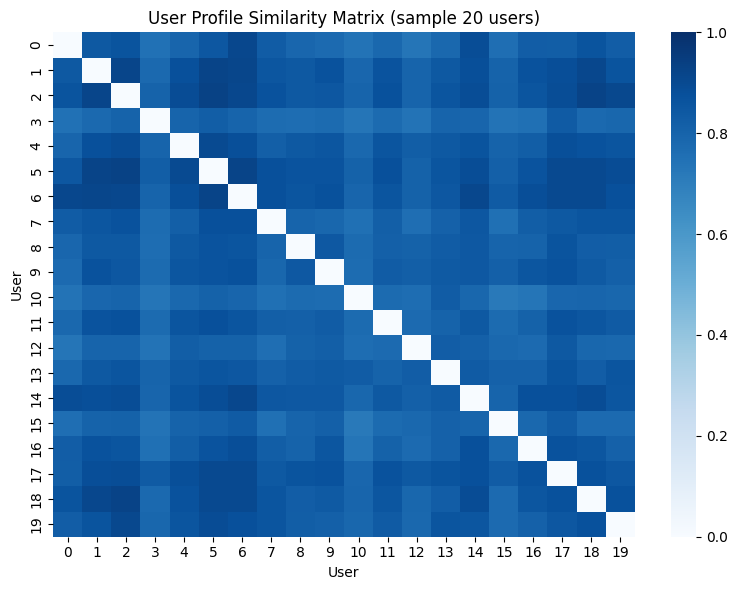


Inter-user profile similarity:
  Mean: 0.851, Std: 0.043
  High similarity pairs (>0.8): 1050


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# ── Profile similarity between users ─────────────────────────────────────────
profile_vecs = []
valid_users  = []
for uid, prof in list(agent._profiles.items())[:50]:
    if prof.long_term.profile_vector is not None:
        profile_vecs.append(prof.long_term.profile_vector)
        valid_users.append(uid)

if len(profile_vecs) >= 2:
    sim_matrix = cosine_similarity(profile_vecs)
    np.fill_diagonal(sim_matrix, 0)  # exclude self-similarity

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(sim_matrix[:20, :20], ax=ax, cmap="Blues", vmin=0, vmax=1)
    ax.set_title("User Profile Similarity Matrix (sample 20 users)")
    ax.set_xlabel("User")
    ax.set_ylabel("User")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "fig_user_profile_similarity.png")
    plt.show()

    # Profile diversity
    upper = sim_matrix[np.triu_indices_from(sim_matrix, k=1)]
    print(f"\nInter-user profile similarity:")
    print(f"  Mean: {upper.mean():.3f}, Std: {upper.std():.3f}")
    print(f"  High similarity pairs (>0.8): {(upper > 0.8).sum()}")